In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn jupyter

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
df = pd.read_csv("water_potability.csv")
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("water_potability.csv")

In [5]:
print(df.shape)
df.info()

(3276, 10)
<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [6]:
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Potability
0    1998
1    1278
Name: count, dtype: int64
Potability
0    60.989011
1    39.010989
Name: proportion, dtype: float64


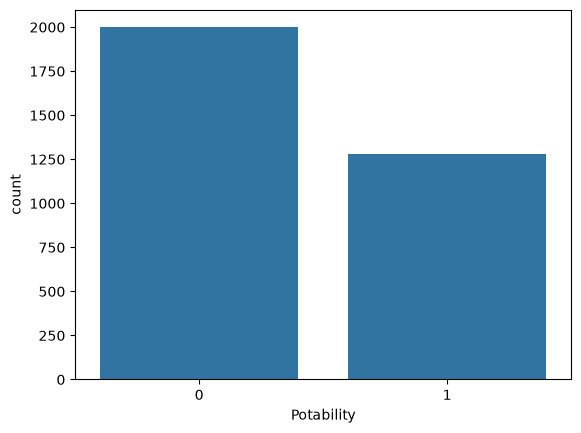

In [7]:
print(df["Potability"].value_counts())
print(df["Potability"].value_counts(normalize=True) * 100)
sns.countplot(x="Potability", data=df)
plt.show()

In [8]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


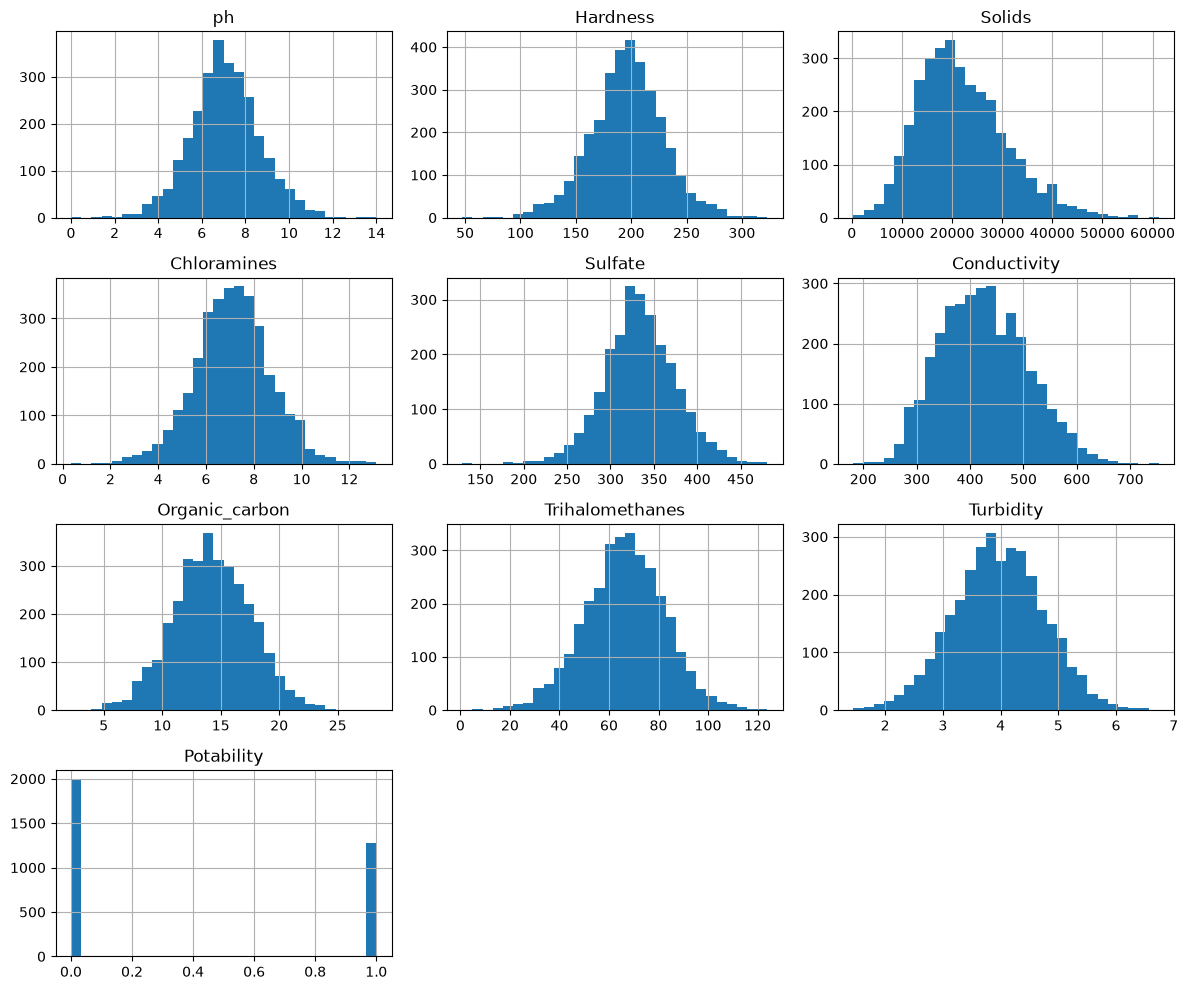

In [9]:
df.hist(figsize=(12, 10), bins=30)
plt.tight_layout()
plt.show()

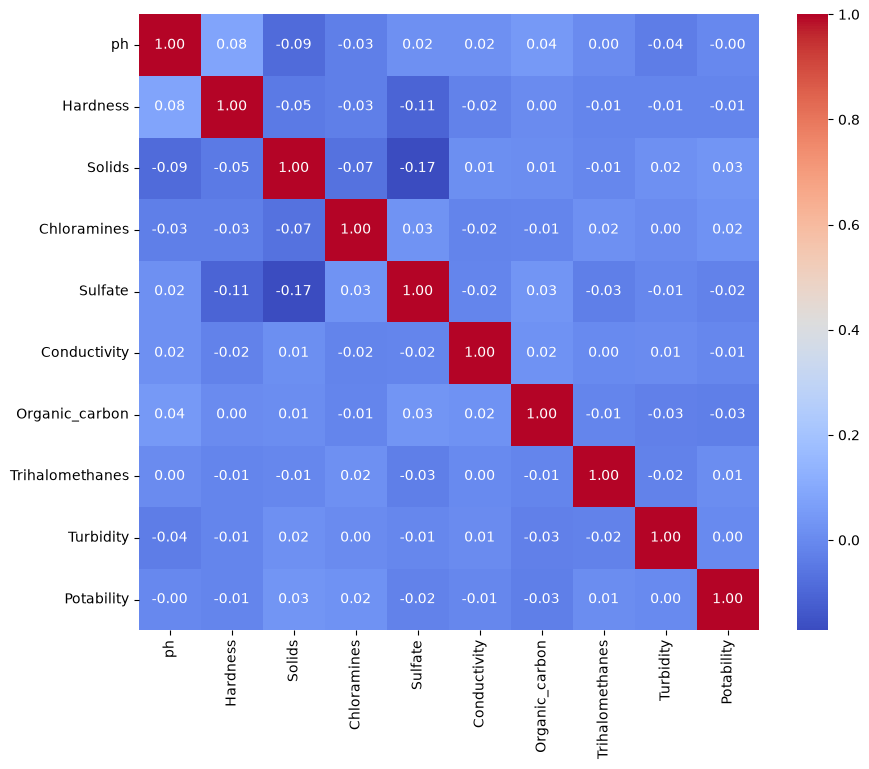

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

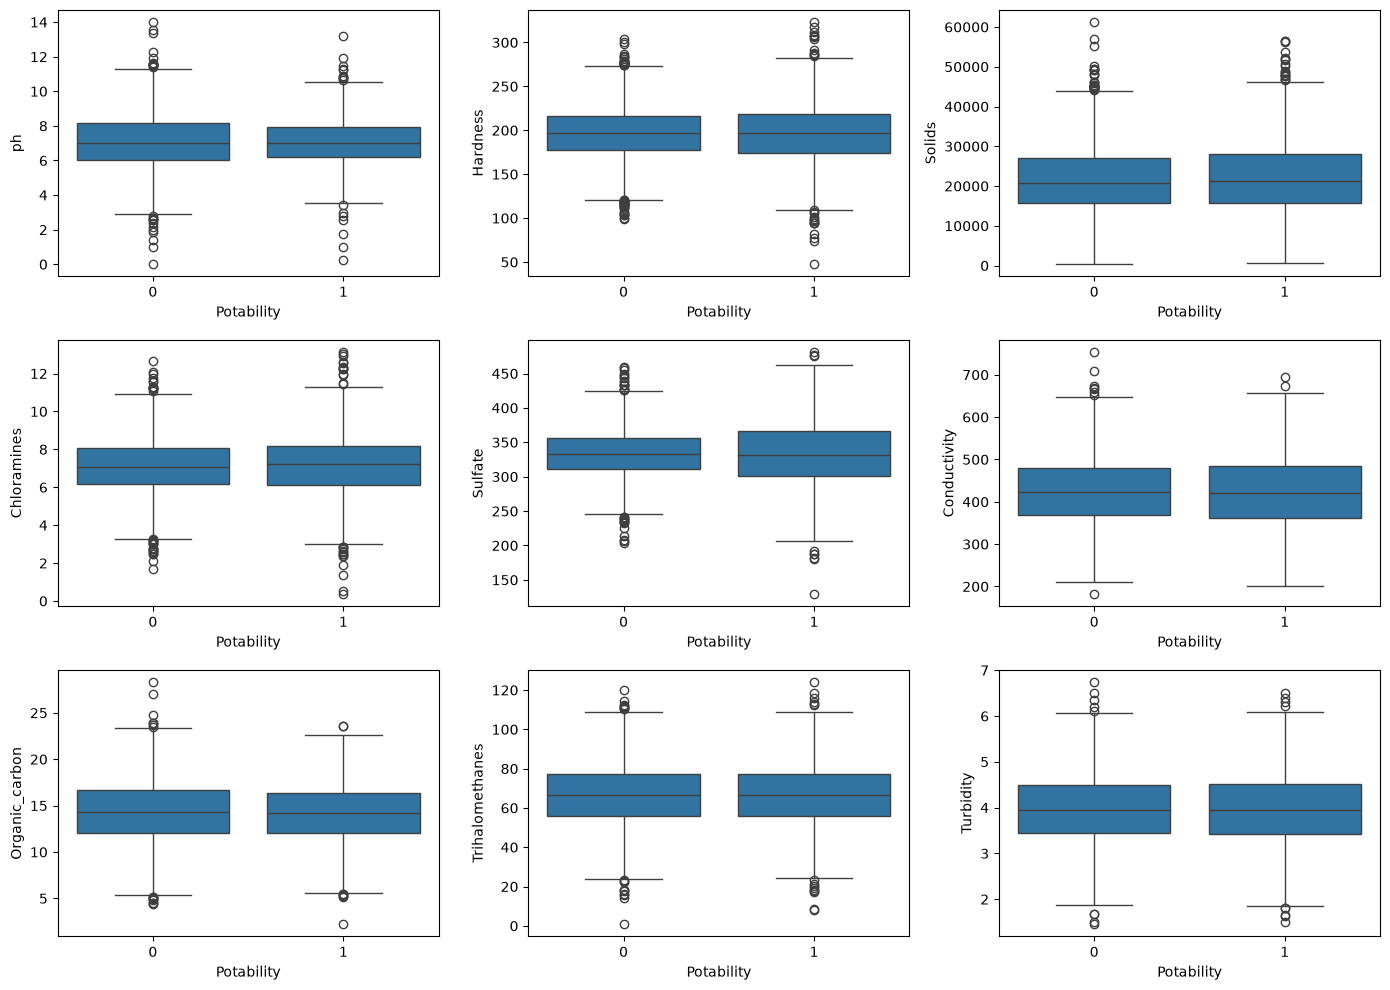

In [11]:
plt.figure(figsize=(14, 10))
for i, col in enumerate(df.columns[:-1], 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x="Potability", y=col, data=df)
plt.tight_layout()
plt.show()

In [12]:
X = df.drop("Potability", axis=1)
y = df["Potability"]
print(X.shape, y.shape)

(3276, 9) (3276,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(2620, 9) (656, 9)


In [14]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

In [15]:
print(np.isnan(X_train_imp).sum(), np.isnan(X_test_imp).sum())

0 0


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

In [17]:
print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

[ 0. -0.  0.  0.  0.  0. -0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [19]:
lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_scaled, y_train)

lr_train_acc = accuracy_score(y_train, lr.predict(X_train_scaled))
lr_test_acc = accuracy_score(y_test, lr.predict(X_test_scaled))
print("Logistic Regression -> Train:", round(lr_train_acc, 4), "Test:", round(lr_test_acc, 4))

Logistic Regression -> Train: 0.5206 Test: 0.5244


In [20]:
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_scaled, y_train)

dt_train_acc = accuracy_score(y_train, dt.predict(X_train_scaled))
dt_test_acc = accuracy_score(y_test, dt.predict(X_test_scaled))
print("Decision Tree -> Train:", round(dt_train_acc, 4), "Test:", round(dt_test_acc, 4))

Decision Tree -> Train: 0.6698 Test: 0.6463


In [21]:
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train_scaled, y_train)

rf_train_acc = accuracy_score(y_train, rf.predict(X_train_scaled))
rf_test_acc = accuracy_score(y_test, rf.predict(X_test_scaled))
print("Random Forest -> Train:", round(rf_train_acc, 4), "Test:", round(rf_test_acc, 4))

Random Forest -> Train: 1.0 Test: 0.6616


In [22]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Train Accuracy": [lr_train_acc, dt_train_acc, rf_train_acc],
    "Test Accuracy": [lr_test_acc, dt_test_acc, rf_test_acc],
})
results["Gap"] = results["Train Accuracy"] - results["Test Accuracy"]
results.round(4)

,Model,Train Accuracy,Test Accuracy,Gap
0,Logistic Regression,0.5206,0.5244,-0.0038
1,Decision Tree,0.6698,0.6463,0.0235
2,Random Forest,1.0000,0.6616,0.3384


In [23]:
from sklearn.metrics import classification_report

for name, model in [("Logistic Regression", lr), ("Decision Tree", dt), ("Random Forest", rf)]:
    print("=====", name, "=====")
    print(classification_report(y_test, model.predict(X_test_scaled)))

===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.63      0.52      0.57       400
           1       0.41      0.53      0.47       256

    accuracy                           0.52       656
   macro avg       0.52      0.53      0.52       656
weighted avg       0.55      0.52      0.53       656

===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.65      0.93      0.76       400
           1       0.64      0.21      0.32       256

    accuracy                           0.65       656
   macro avg       0.64      0.57      0.54       656
weighted avg       0.65      0.65      0.59       656

===== Random Forest =====
              precision    recall  f1-score   support

           0       0.67      0.89      0.76       400
           1       0.63      0.31      0.42       256

    accuracy                           0.66       656
   macro avg       0.65      0.60      0.59 

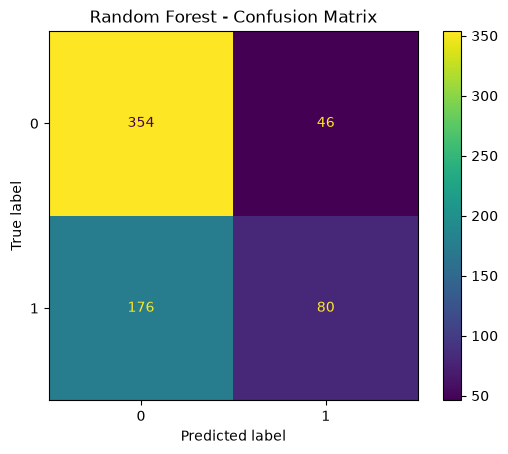

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(rf, X_test_scaled, y_test)
plt.title("Random Forest - Confusion Matrix")
plt.show()

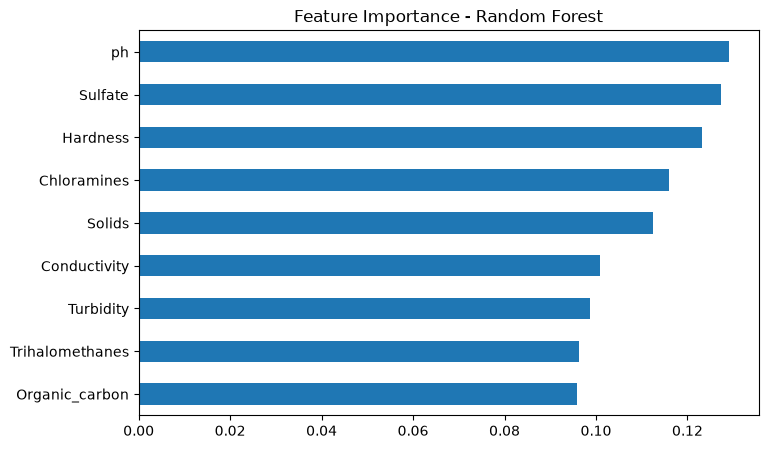

In [25]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance - Random Forest")
plt.show()

In [26]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [1, 3, 5],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)
grid.fit(X_train_scaled, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 4))

Best settings: {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200}
Best cross-validation accuracy: 0.6718


In [27]:
best_rf = grid.best_estimator_

tuned_train_acc = accuracy_score(y_train, best_rf.predict(X_train_scaled))
tuned_test_acc = accuracy_score(y_test, best_rf.predict(X_test_scaled))
print("Tuned Random Forest -> Train:", round(tuned_train_acc, 4), "Test:", round(tuned_test_acc, 4))

from sklearn.metrics import classification_report
print(classification_report(y_test, best_rf.predict(X_test_scaled)))

Tuned Random Forest -> Train: 0.9943 Test: 0.6631
              precision    recall  f1-score   support

           0       0.67      0.89      0.76       400
           1       0.64      0.31      0.42       256

    accuracy                           0.66       656
   macro avg       0.66      0.60      0.59       656
weighted avg       0.66      0.66      0.63       656



In [29]:
rf_bal = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=42
)
rf_bal.fit(X_train_scaled, y_train)

bal_train_acc = accuracy_score(y_train, rf_bal.predict(X_train_scaled))
bal_test_acc = accuracy_score(y_test, rf_bal.predict(X_test_scaled))
print("Balanced RF -> Train:", round(bal_train_acc, 4), "Test:", round(bal_test_acc, 4))
print(classification_report(y_test, rf_bal.predict(X_test_scaled)))

Balanced RF -> Train: 0.8477 Test: 0.6479
              precision    recall  f1-score   support

           0       0.69      0.77      0.73       400
           1       0.56      0.46      0.50       256

    accuracy                           0.65       656
   macro avg       0.62      0.61      0.62       656
weighted avg       0.64      0.65      0.64       656



In [30]:
final = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "Tuned Random Forest", "Balanced Random Forest"],
    "Train Accuracy": [lr_train_acc, dt_train_acc, rf_train_acc, tuned_train_acc, bal_train_acc],
    "Test Accuracy": [lr_test_acc, dt_test_acc, rf_test_acc, tuned_test_acc, bal_test_acc],
})
final["Gap"] = final["Train Accuracy"] - final["Test Accuracy"]
final.round(4)

,Model,Train Accuracy,Test Accuracy,Gap
0,Logistic Regression,0.5206,0.5244,-0.0038
1,Decision Tree,0.6698,0.6463,0.0235
2,Random Forest,1.0000,0.6616,0.3384
3,Tuned Random Forest,0.9943,0.6631,0.3312
4,Balanced Random Forest,0.8477,0.6479,0.1998


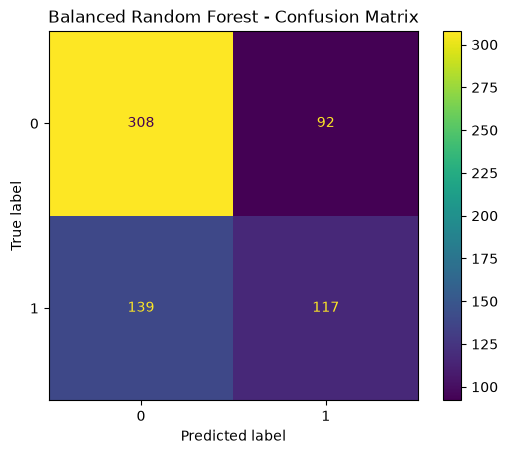

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(rf_bal, X_test_scaled, y_test)
plt.title("Balanced Random Forest - Confusion Matrix")
plt.show()

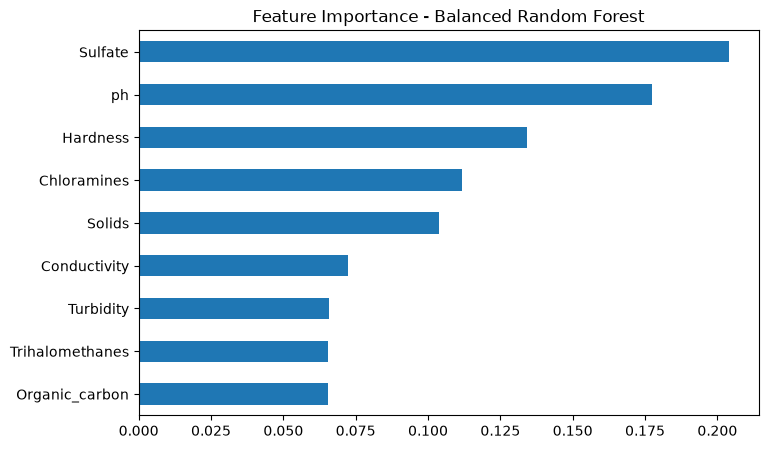

In [33]:
importances = pd.Series(rf_bal.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance - Balanced Random Forest")
plt.show()

In [34]:
#testing 

In [35]:
# 1. Type the water sample values here
new_sample = pd.DataFrame([{
    "ph": 7.0,
    "Hardness": 200.0,
    "Solids": 20000.0,
    "Chloramines": 7.0,
    "Sulfate": 330.0,
    "Conductivity": 420.0,
    "Organic_carbon": 14.0,
    "Trihalomethanes": 66.0,
    "Turbidity": 4.0,
}])

# 2. Apply the same preprocessing used for training
new_imputed = imputer.transform(new_sample)
new_scaled = scaler.transform(new_imputed)

# 3. Predict
prediction = rf_bal.predict(new_scaled)[0]
probability = rf_bal.predict_proba(new_scaled)[0]

print("Prediction:", "SAFE (1)" if prediction == 1 else "NOT SAFE (0)")
print("Probability not safe:", round(probability[0], 3))
print("Probability safe:", round(probability[1], 3))

Prediction: NOT SAFE (0)
Probability not safe: 0.568
Probability safe: 0.432


In [36]:
# real row from our data

In [37]:
sample = X_test.iloc[[0]]
pred = rf_bal.predict(scaler.transform(imputer.transform(sample)))[0]
print("Model predicted:", pred, "| Actual answer:", y_test.iloc[0])

Model predicted: 0 | Actual answer: 1


In [38]:
# real row (10)

In [39]:
sample = X_test.iloc[:10]
preds = rf_bal.predict(scaler.transform(imputer.transform(sample)))

compare = pd.DataFrame({"Predicted": preds, "Actual": y_test.iloc[:10].values})
compare["Correct"] = compare["Predicted"] == compare["Actual"]
compare

,Predicted,Actual,Correct
0,0,1,False
1,0,0,True
2,0,0,True
3,0,0,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,1,False
9,1,1,True
